# Cheaper fares, cleaner air? The 50 cent fare and Queensland's environment

On 5 August 2024 every public transport fare in Queensland dropped to 50 cents. This notebook asks whether that changed
how much petrol Queenslanders burn, how many cars are on the road, and how clean the air is beside the road.
Part 1 looks at the data. Part 2 forecasts what would have happened without the fare cut and compares it with what did happen.

The red line on every chart is 5 August 2024. Trips, petrol and cars are all counted per person, because Queensland's population
grows about 2 per cent a year and more people means more trips and more petrol with no change in behaviour.

## Data used

All government open data.

| Dataset | What it gives us | Link |
|---|---|---|
| ABS national, state and territory population | Population by state, quarterly, for every per-person figure | [abs.gov.au](https://www.abs.gov.au/statistics/people/population/national-state-and-territory-population/latest-release) |
| Translink monthly performance data | Weekly public transport trips in South East Queensland since 2012 | [data.qld.gov.au](https://www.data.qld.gov.au/dataset/translink-monthly-performance-data) |
| Australian Petroleum Statistics | Monthly petrol and diesel sales by state, including diesel sold through service stations | [energy.gov.au](https://www.energy.gov.au/energy-data/australian-petroleum-statistics) |
| Queensland fuel price reporting | Pump prices at every servo, for the dollars saved | [data.qld.gov.au](https://www.data.qld.gov.au/dataset?q=fuel+price+reporting) |
| Brisbane City Council key corridor traffic | Weekday traffic counts on 18 main Brisbane roads, monthly since 2013 | [current](https://data.brisbane.qld.gov.au/explore/dataset/traffic-management-key-corridor-monthly-performance-report) and [2013 to 2019](https://data.brisbane.qld.gov.au/explore/dataset/traffic-volume-key-corridors-performance-report) |
| Queensland air quality monitoring | Hourly NO2 and weather at the South Brisbane and Springwood stations | [data.qld.gov.au](https://www.data.qld.gov.au/dataset?q=air+quality+monitoring) |
| Australian public holidays | Holiday dates, an input for the NO2 and traffic models | [data.gov.au](https://data.gov.au/data/dataset/australian-holidays-machine-readable-dataset) |
| Queensland school term dates | School holidays, an input for the NO2 and traffic models | [education.qld.gov.au](https://education.qld.gov.au/about-us/calendar/term-dates) |
| TMR vehicle registrations, new and transfers | New cars registered in Queensland each month by fuel type | [data.qld.gov.au](https://www.data.qld.gov.au/dataset/vehicle-registration-new-and-transfers-test) |
| BITRE Road Vehicles Australia, January 2025 | Every registered vehicle by fuel type and state, table 5 | [bitre.gov.au](https://www.bitre.gov.au/publications/2025/road-vehicles-australia-january-2025) |

In [1]:
import warnings, itertools
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor

plt.rcParams.update({"figure.figsize": (10, 4), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e1e0d9", "axes.axisbelow": True, "font.size": 13,
                     "axes.titlesize": 14, "axes.labelsize": 13, "xtick.labelsize": 12, "ytick.labelsize": 12,
                     "legend.fontsize": 12, "axes.titlelocation": "left", "legend.frameon": False})
pd.set_option("display.precision", 1)

CLEAN, RAW, MODEL = "../data/clean", "../data/raw", "../model_ready"
FARE_CUT = pd.Timestamp("2024-08-05")
YEAR_BEFORE = slice("2023-08-01", "2024-07-31")
YEAR_AFTER = slice("2024-08-01", "2025-07-31")
BLUE, ORANGE, GREEN, PURPLE, GREY, LIGHT_GREY, RED = "#2a78d6", "#eb6834", "#1baf7a", "#4a3aa7", "#898781", "#c3c2b7", "#e34948"


def fare_line(ax):
    ax.axvline(FARE_CUT, color=RED, lw=1.2)

## The data

In [2]:
# Population: the ABS counts people only every three months. scripts/population.py fills the months in between by sharing
# the growth out evenly by day (Dec 2024 to Mar 2025 grew 28,984 over 90 days, so 31 January gets 31/90 of it), and projects
# the months after March 2026 at the latest yearly growth. Everything per person divides by this.
pop = pd.read_csv(f"{CLEAN}/population_by_state_monthly.csv", parse_dates=["month"]).pivot(index="month", columns="State", values="population")
growth = 100 * (pop.loc["2026-06-01", "QLD"] / pop.loc["2019-06-01", "QLD"] - 1)
print(f"Queensland population: {pop.loc['2019-06-01', 'QLD']/1e6:.2f} million in mid 2019, {pop.loc['2026-06-01', 'QLD']/1e6:.2f} million in mid 2026, up {growth:.0f} per cent")

Queensland population: 5.09 million in mid 2019, 5.76 million in mid 2026, up 13 per cent


In [3]:
# Weekly public transport trips in South East Queensland, all modes, turned into trips per 1,000 Queenslanders.
trips = pd.read_csv(f"{CLEAN}/seq_weekly_trips.csv", parse_dates=["week_ending"]).set_index("week_ending")["trips"]
trips = trips.reindex(pd.date_range(trips.index.min(), trips.index.max(), freq="W-SUN"))     # nine missing weeks in 2026 show as a gap
pop_weekly = pop["QLD"].reindex(pop.index.union(trips.index)).interpolate(method="time").reindex(trips.index)
trips_per_1000 = 1000 * trips / pop_weekly

In [4]:
# Monthly petrol sales by state, as litres per person. NSW and Victoria together are the comparison, because they had no fare cut.
petrol = pd.read_csv(f"{MODEL}/petrol_monthly.csv", parse_dates=["month"]).set_index("month")
petrol_vs_control = 100 * petrol["qld_litres_pp"] / petrol["ctrl_litres_pp"]

In [5]:
# Weekday traffic on 18 main Brisbane roads, counted by the city council, as cars per 1,000 Queenslanders.
traffic = pd.read_csv(f"{MODEL}/traffic_monthly.csv", parse_dates=["month"]).set_index("month")

In [6]:
# Nitrogen dioxide (NO2) from the Queensland Government's South Brisbane air monitoring station, which sits beside the Pacific Motorway
# (South East Freeway) at Clarence Corner, where the freeway meets Vulture Street and Stanley Street. Hourly for the chart, daily with weather for the models.
no2_hourly = pd.read_csv(f"{CLEAN}/no2_hourly_selected_sites.csv", parse_dates=["ts"])
no2_hourly = no2_hourly[no2_hourly["site"] == "southbrisbane"].set_index("ts")["no2_ppb"]
air = pd.read_csv(f"{MODEL}/no2_daily.csv", parse_dates=["date"]).set_index("date")
rain_missing = air["rain_mm"].isna()             # the rain gauge sent nothing on 198 days, 189 of them January to July 2016
air["rain_mm"] = air["rain_mm"].fillna(0)        # set to 0 rain here; Part 2 reruns NO2 without those days to check

## Part 1. What the data shows

In [7]:
# The year before the fare cut against the year after, per person. One line per thing we care about.
summary = pd.DataFrame({
    "Year before": [trips_per_1000[YEAR_BEFORE].mean(), petrol.loc[YEAR_BEFORE, "qld_litres_pp"].mean(),
                    traffic.loc[YEAR_BEFORE, "veh_per_1000_pop"].mean(), air.loc[YEAR_BEFORE, "no2_ppb"].mean()],
    "Year after": [trips_per_1000[YEAR_AFTER].mean(), petrol.loc[YEAR_AFTER, "qld_litres_pp"].mean(),
                   traffic.loc[YEAR_AFTER, "veh_per_1000_pop"].mean(), air.loc[YEAR_AFTER, "no2_ppb"].mean()],
}, index=["Public transport trips per week, per 1,000 people", "Petrol per person per month, litres",
          "Weekday cars on 18 Brisbane roads, per 1,000 people", "NO2 beside the road, ppb"])
summary["Change"] = (100 * (summary["Year after"] / summary["Year before"] - 1)).round(1).astype(str) + "%"
summary.round(1)

,Year before,Year after,Change
"Public transport trips per week, per 1,000 people",582.1,664.2,14.1%
"Petrol per person per month, litres",51.0,48.8,-4.1%
"Weekday cars on 18 Brisbane roads, per 1,000 people",139.3,138.2,-0.8%
"NO2 beside the road, ppb",11.8,12.9,9.2%


This table is the simplest possible check: the average of the year before the fare cut against the average of the year after,
everything per person. Public transport use jumped by about 14 per cent. Petrol use fell by about 4 per cent, but it falls most
years anyway. Cars on Brisbane's main roads barely moved. NO2 was higher in the year after, which is mostly weather:
chart 4 compares like with like. The four charts below show each of these over time.

**TLDR:** more public transport, a bit less petrol, same cars, same air.

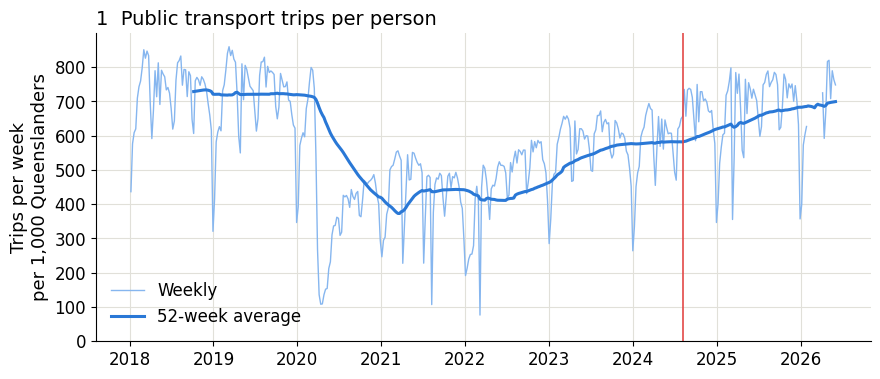

In [8]:
s = trips_per_1000["2018":]
fig, ax = plt.subplots()
ax.plot(s.index, s, color="#86b6ef", lw=1.0, label="Weekly")
ax.plot(s.index, s.rolling(52, min_periods=40).mean(), color=BLUE, lw=2.2, label="52-week average")
fare_line(ax)
ax.set_ylim(0, None)
ax.set_ylabel("Trips per week\nper 1,000 Queenslanders")
ax.set_title("1  Public transport trips per person")
ax.legend(loc="lower left")
plt.show()

Trips per person halved in 2020 and climbed back slowly. By mid 2024 that recovery had stalled: the 52-week average was flat and
trips were running 0 to 3 per cent above a year earlier. From the month of the fare cut they ran 8 to 24 per cent above a year
earlier for twelve months. The dips are school holidays; the deep one in March 2025 is Cyclone Alfred.

**TLDR:** the COVID recovery had stalled before the fare cut; the fare cut restarted it, and the rise stayed.

Year before the fare cut: 99.4%   year after: 96.8%


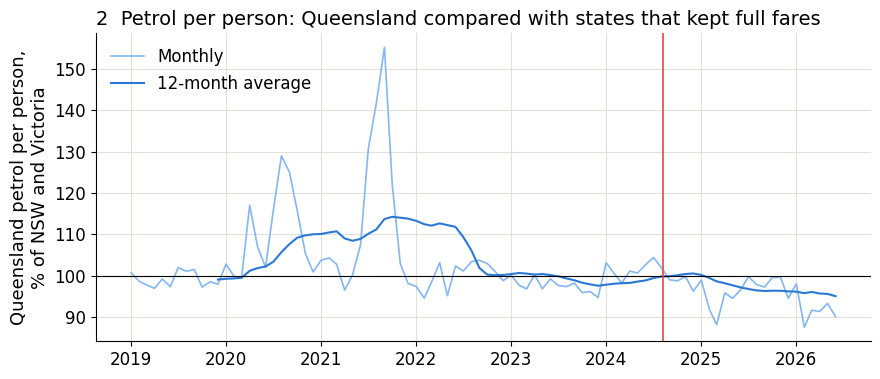

In [9]:
s = petrol_vs_control["2019":]
fig, ax = plt.subplots()
ax.plot(s.index, s, color="#86b6ef", lw=1.2, label="Monthly")
ax.plot(s.index, s.rolling(12).mean(), color=BLUE, label="12-month average")
ax.axhline(100, color="black", lw=0.8)
fare_line(ax)
ax.set_ylabel("Queensland petrol per person,\n% of NSW and Victoria")
ax.set_title("2  Petrol per person: Queensland compared with states that kept full fares")
ax.legend(loc="upper left")
print(f"Year before the fare cut: {petrol_vs_control[YEAR_BEFORE].mean():.1f}%   year after: {petrol_vs_control[YEAR_AFTER].mean():.1f}%")
plt.show()

Compared with NSW and Victoria, Queenslanders used about the same petrol per person before the fare cut and about 3 per cent
less after it. The bumps in 2020 and 2021 are the Sydney and Melbourne lockdowns: this line can move for reasons that have
nothing to do with Queensland, which is why Part 2 uses proper models.

**TLDR:** compared with states that kept full fares, Queensland is buying about 3 per cent less petrol per person since the fare cut.

In [10]:
# The same comparison as a table, one row per fare year (August to July), from 2014 when the models' training starts.
# 2025-26 has eleven months (to June 2026). No model here, just the two series from petrol_monthly.csv.
since_2014 = petrol.loc["2014-08-01":]
fare_year = (since_2014.index - pd.DateOffset(months=7)).year
share = since_2014.groupby(fare_year)[["qld_litres_pp", "ctrl_litres_pp"]].mean()
share["QLD as % of NSW+VIC"] = 100 * share["qld_litres_pp"] / share["ctrl_litres_pp"]
share.index = [f"Aug {y} - Jul {y + 1}" + (" (COVID)" if y in (2019, 2020, 2021) else "") for y in share.index]
share.columns = ["QLD litres per person per month", "NSW+VIC litres per person per month", "QLD as % of NSW+VIC"]
share.round(1)

,QLD litres per person per month,NSW+VIC litres per person per month,QLD as % of NSW+VIC
Aug 2014 - Jul 2015,67.0,65.3,102.5
Aug 2015 - Jul 2016,65.5,63.7,102.9
Aug 2016 - Jul 2017,63.0,63.2,99.7
Aug 2017 - Jul 2018,62.1,61.5,101.0
Aug 2018 - Jul 2019,59.6,59.8,99.5
Aug 2019 - Jul 2020 (COVID),54.1,52.8,102.5
Aug 2020 - Jul 2021 (COVID),56.0,51.4,108.9
Aug 2021 - Jul 2022 (COVID),52.7,49.4,106.8
Aug 2022 - Jul 2023,52.3,52.4,99.9
Aug 2023 - Jul 2024,51.0,51.3,99.4


For the seven normal years before the fare cut (COVID years aside), a Queenslander used within 1 to 3 per cent of what a person in
NSW or Victoria used. After the fare cut, 3 per cent less, then 5 per cent less, the lowest share in the table. This is the raw data,
with no model. The models are still needed to say how much of a gap is normal wobble, to take out seasons and month length, and to
turn the gap into litres, carbon and dollars; the raw numbers show the drop, the models measure it.

**TLDR:** Queensland tracked NSW and Victoria for years, then fell 3 and then 5 per cent behind them after the fare cut.

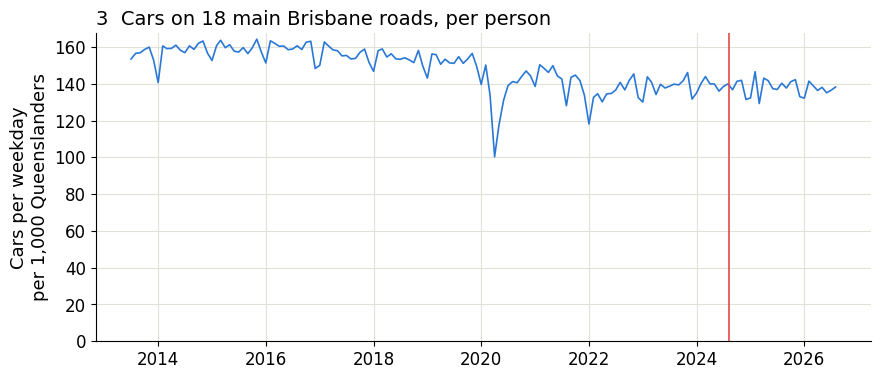

In [11]:
s = traffic["veh_per_1000_pop"]
fig, ax = plt.subplots()
ax.plot(s.index, s, color=BLUE, lw=1.2)
fare_line(ax)
ax.set_ylim(0, None)
ax.set_ylabel("Cars per weekday\nper 1,000 Queenslanders")
ax.set_title("3  Cars on 18 main Brisbane roads, per person")
plt.show()

Traffic per person was steady until COVID, dropped in 2020 and never quite came back, as more people work from home.
There is no step at the red line. The fare cut did not take cars off the road.

**TLDR:** the fare cut did not take cars off Brisbane's main roads.

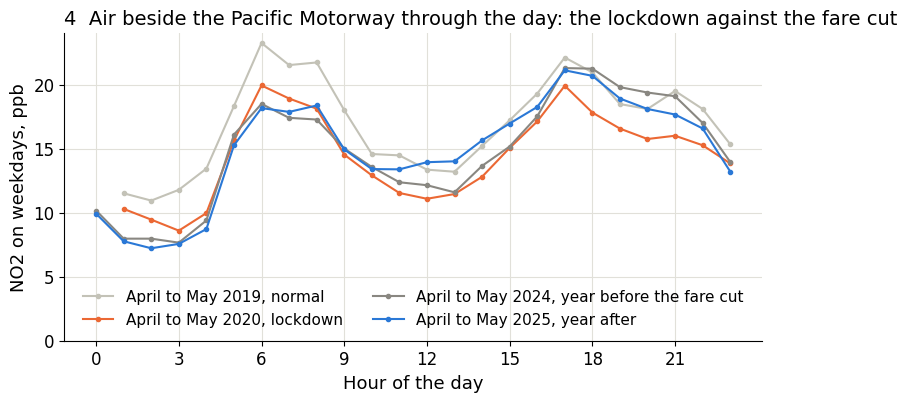

In [12]:
weekday = no2_hourly[no2_hourly.index.dayofweek < 5]
fig, ax = plt.subplots(figsize=(9, 4))
for label, year, colour in [("April to May 2019, normal", 2019, LIGHT_GREY), ("April to May 2020, lockdown", 2020, ORANGE),
                            ("April to May 2024, year before the fare cut", 2024, GREY), ("April to May 2025, year after", 2025, BLUE)]:
    window = weekday[f"{year}-04-01":f"{year}-05-31"]
    by_hour = window.groupby(window.index.hour).mean()
    ax.plot(by_hour.index, by_hour, color=colour, marker="o", ms=3, label=label)
ax.set_xticks(range(0, 24, 3))
ax.set_xlabel("Hour of the day")
ax.set_ylabel("NO2 on weekdays, ppb")
ax.set_ylim(0, None)
ax.set_title("4  Air beside the Pacific Motorway through the day: the lockdown against the fare cut")
ax.legend(loc="lower center", ncol=2, fontsize=11)
plt.show()

The sensor is the Queensland Government's South Brisbane station, beside the Pacific Motorway where it meets Vulture Street near the
Gabba, one of the busiest spots in the city. The 2020 lockdown (orange) clearly cut the morning peak, so a real drop in traffic does
show up in this data. The year after the fare cut (blue) sits on top of the year before (grey) at every hour. Whatever cars the fare
removed, it was far too few to see.

**TLDR:** a lockdown shows up in the air beside the freeway; the fare cut does not.

## Part 2. What would have happened without the fare cut?

A before-and-after comparison can be fooled by anything else that changed at the same time: petrol prices, the weather,
cleaner cars. So three different models (linear regression, gradient boosting, random forest) learn from the years before the
fare cut and predict what each series would have done without it. The difference between the prediction and what actually
happened is the effect of the fare. If three different models agree, the result does not depend on which one we picked.

Each file has a `split` column. `train` runs to July 2023, `validation` is August 2023 to July 2024, `policy` is everything
after the fare cut, and `unused` is COVID and other periods nothing should learn from.

1. Tune. Hold back the last year of the training rows, fit each candidate setting on the rows before it, keep the setting with the lowest error on that year.
2. Test. Fit on all the training rows, predict the validation year. The error there says how good the model is on a normal year it never saw.
3. Predict. Fit again on training plus validation, predict the policy months. The gap between actual and predicted is the effect.
4. Repeat 2 and 3 with one input changed, the extra run, to show the answer does not hinge on that choice.

In [13]:
# What to predict in each file and which columns the models may use. Petrol learns from petrol use in the comparison states.
# NO2 learns from the weather and the calendar, with post_covid marking the step down in 2020 that never came back.
# Traffic learns from school and public holidays. The extra run changes one input each.
weather = ["wind_speed", "wind_u", "wind_v", "temp_c", "temp_min_c", "humidity_pct", "pressure_hpa", "rain_mm",
           "is_public_holiday", "is_school_holiday"]
files = {
    "Petrol": dict(df=petrol, target="qld_litres_pp", daily=False, calendar=["month_of_year"], step=None,
                   inputs={"main": ["ctrl_litres_pp", "days_in_month"], "extra": ["ctrl_all_litres_pp", "days_in_month"]},
                   ratio={"main": "ctrl_litres_pp", "extra": "ctrl_all_litres_pp"},
                   label="Petrol, litres per person per month", unit="litres per person", ylim=(40, 60)),
    "NO2": dict(df=air, target="no2_ppb", daily=True, calendar=["day_of_week", "day_of_year"], step="post_covid",
                inputs={"main": weather, "extra": weather + ["bg_no2_ppb"]}, ratio=None,
                label="NO2 beside the road, South Brisbane", unit="ppb, monthly mean", ylim=(0, 25)),
    "Cars": dict(df=traffic, target="veh_per_1000_pop", daily=False, calendar=["month_of_year"], step="post_covid",
                 inputs={"main": ["school_holiday_share", "public_holiday_weekdays"],
                         "extra": ["school_holiday_share", "public_holiday_weekdays", "aus_ulp_price_cpl"]}, ratio=None,
                 label="Weekday cars on 18 Brisbane roads, per person", unit="cars per weekday\nper 1,000 people", ylim=(100, 175)),
}
for f in files.values():
    cols = list(dict.fromkeys(f["inputs"]["main"] + f["inputs"]["extra"] + f["calendar"] + ([f["step"]] if f["step"] else []) + ["t"]))
    f["df"][cols] = f["df"][cols].ffill().bfill()     # the few empty input cells take the value from the day before

In [14]:
def score(actual, predicted):
    # error: average percentage miss, row by row. bias: total predicted against total actual.
    # gap: total actual against total predicted, so a negative gap means less than expected.
    a, p = np.asarray(actual, float), np.asarray(predicted, float)
    ok = np.isfinite(a) & np.isfinite(p)
    a, p = a[ok], p[ok]
    return {"error": 100 * np.mean(np.abs(p - a) / a),
            "bias": 100 * (p.sum() - a.sum()) / a.sum(),
            "gap": 100 * (a.sum() - p.sum()) / p.sum()}

In [15]:
def linear_inputs(f, run):
    # Month and weekday become 0/1 columns, because December is not twelve times January.
    # Day of year becomes a sine and cosine so the seasons come out as a smooth wave.
    df = f["df"]
    parts = [df[f["inputs"][run]].astype(float)]
    if f["step"]:
        parts.append(df[[f["step"]]].astype(float))
    if "month_of_year" in f["calendar"]:
        parts.append(pd.get_dummies(df["month_of_year"], prefix="m").reindex(columns=[f"m_{i}" for i in range(2, 13)], fill_value=0).astype(float))
    if "day_of_week" in f["calendar"]:
        parts.append(pd.get_dummies(df["day_of_week"], prefix="dow").reindex(columns=[f"dow_{i}" for i in range(1, 7)], fill_value=0).astype(float))
    if "day_of_year" in f["calendar"]:
        angle = 2 * np.pi * df["day_of_year"] / 365.25
        parts.append(pd.DataFrame({"doy_sin": np.sin(angle), "doy_cos": np.cos(angle)}, index=df.index))
    return pd.concat(parts, axis=1)


def tree_inputs(f, run):
    # Trees are fine with the calendar columns as plain numbers. NO2 and traffic also get t, a running count of days
    # or months, so the trees hold the latest level rather than an old one.
    cols = f["inputs"][run] + f["calendar"] + (["t"] if f["target"] in ("no2_ppb", "veh_per_1000_pop") else [])
    return f["df"][cols].astype(float)

### The models

Each model is a function with the same shape: fit on some rows, predict some other rows, hand back the predictions.
Each also lists the settings worth trying; the tuning step picks the best of them.

**1. Linear regression.** Draws the straightest line through the training data: Queensland petrol is this much times the other
states' petrol, plus a fixed amount for each month. Simple, hard to fool, nothing to tune.

In [16]:
def fit_linear(f, fit_rows, predict_rows, run, params):
    X = linear_inputs(f, run)
    m = LinearRegression().fit(X.loc[fit_rows], f["df"].loc[fit_rows, f["target"]])
    return pd.Series(m.predict(X.loc[predict_rows]), index=predict_rows)


def linear_settings(f):
    return [{}]          # plain linear regression has nothing to tune

**2. Gradient boosting.** Builds a few hundred small decision trees one after another, each one fixing the mistakes of the ones
before. It can bend to any shape, which is why it is kept small for petrol (93 training rows). Settings tuned: how deep each
tree goes, how many trees, how many rows a leaf must hold.

In [17]:
def fit_boosting(f, fit_rows, predict_rows, run, params):
    # For petrol the trees predict the ratio to the comparison states and multiply back afterwards: trees cannot predict
    # a value lower than anything they saw in training, and petrol use keeps falling.
    X, y = tree_inputs(f, run), f["df"][f["target"]]
    ctrl = f["df"][f["ratio"][run]] if f["ratio"] else None
    target = y / ctrl if ctrl is not None else y
    m = HistGradientBoostingRegressor(random_state=0, **params).fit(X.loc[fit_rows], target.loc[fit_rows])
    pred = pd.Series(m.predict(X.loc[predict_rows]), index=predict_rows)
    return pred * ctrl.loc[predict_rows] if ctrl is not None else pred


def boosting_settings(f):
    grid = lambda **o: [dict(zip(o, v)) for v in itertools.product(*o.values())]
    if f["daily"]:
        return grid(max_depth=[3, 6], max_iter=[200, 500], learning_rate=[0.05], min_samples_leaf=[20])
    return grid(max_depth=[2, 3], max_iter=[100, 300], learning_rate=[0.05], min_samples_leaf=[5, 20])

**3. Random forest.** Builds a few hundred decision trees independently, each on a random slice of the data, and averages their
answers. Less likely to chase noise than a single tree. Settings tuned: how deep each tree goes and how many rows a leaf must hold.

In [18]:
def fit_forest(f, fit_rows, predict_rows, run, params):
    # Same ratio trick as gradient boosting for petrol.
    X, y = tree_inputs(f, run), f["df"][f["target"]]
    ctrl = f["df"][f["ratio"][run]] if f["ratio"] else None
    target = y / ctrl if ctrl is not None else y
    m = RandomForestRegressor(random_state=0, n_jobs=-1, **params).fit(X.loc[fit_rows], target.loc[fit_rows])
    pred = pd.Series(m.predict(X.loc[predict_rows]), index=predict_rows)
    return pred * ctrl.loc[predict_rows] if ctrl is not None else pred


def forest_settings(f):
    grid = lambda **o: [dict(zip(o, v)) for v in itertools.product(*o.values())]
    if f["daily"]:
        return grid(n_estimators=[300], max_depth=[8, 12], min_samples_leaf=[20, 50])
    return grid(n_estimators=[300], max_depth=[3, 5], min_samples_leaf=[5, 20])

In [19]:
models = {"Linear regression": fit_linear, "Gradient boosting": fit_boosting, "Random forest": fit_forest}
settings = {"Linear regression": linear_settings, "Gradient boosting": boosting_settings, "Random forest": forest_settings}
COLOURS = {"Linear regression": ORANGE, "Gradient boosting": GREEN, "Random forest": PURPLE, "Copy last year": GREY}


def settings_to_try(model, f):
    return settings[model](f)

**4. Copy last year.** The simplest model: each month equals the same month a year earlier (for daily NO2, the same weekday
52 weeks earlier), going back another year if that month is inside the forecast. Nothing to learn, so it is the benchmark.

In [20]:
def copy_last_year(f, predict_rows):
    # The simplest model and the benchmark: the same month (or same weekday) one year earlier, from before the forecast starts.
    y, start = f["df"][f["target"]], predict_rows.min()
    step = pd.Timedelta(days=364) if f["daily"] else pd.DateOffset(months=12)
    out = []
    for when in predict_rows:
        back = when - step
        while back >= start:
            back -= step
        out.append(y.get(back, np.nan))
    return pd.Series(out, index=predict_rows)

In [21]:
TUNE_START = pd.Timestamp("2022-08-01")        # the year held back inside the training rows for tuning


def rows_of(f):
    # The row groups one file gives us. Rows with no target value are never fitted or scored.
    df, target = f["df"], f["target"]
    ok = df[target].notna()
    train = df.index[(df["split"] == "train") & ok]
    validation = df.index[(df["split"] == "validation") & ok]
    policy = df.index[(df["split"] == "policy") & ok]
    return train, validation, policy


def tune(f, model, train):
    # Fit on the training rows before August 2022, score on the last training year, keep the best setting.
    fit, held_back = train[train < TUNE_START], train[train >= TUNE_START]
    tried = []
    for params in settings_to_try(model, f):
        pred = models[model](f, fit, held_back, "main", params)
        tried.append((score(f["df"].loc[held_back, f["target"]], pred)["error"], params))
    return min(tried, key=lambda x: x[0])[1]

In [22]:
def run_file(name):
    # Steps 1 to 4 for one file: tune, test on the validation year, predict the policy months, then the extra run.
    f = files[name]
    df, target = f["df"], f["target"]
    train, validation, policy = rows_of(f)
    rows = []
    for model, fit in models.items():
        best = tune(f, model, train)
        for run in ("main", "extra"):
            val_pred = fit(f, train, validation, run, best)
            pol_pred = fit(f, train.union(validation), policy, run, best)
            v, p = score(df.loc[validation, target], val_pred), score(df.loc[policy, target], pol_pred)
            rows.append({"file": name, "model": model, "run": run, "error": v["error"], "bias": v["bias"], "gap": p["gap"]})
            predictions[(name, model, run)] = pd.concat([val_pred, pol_pred])
    val_pred, pol_pred = copy_last_year(f, validation), copy_last_year(f, policy)
    v, p = score(df.loc[validation, target], val_pred), score(df.loc[policy, target], pol_pred)
    rows.append({"file": name, "model": "Copy last year", "run": "main", "error": v["error"], "bias": v["bias"], "gap": p["gap"]})
    predictions[(name, "Copy last year", "main")] = pd.concat([val_pred, pol_pred])
    print(f"{name}: done, {len(train)} training rows")
    return pd.DataFrame(rows)


predictions = {}
results = pd.concat([run_file(name) for name in files], ignore_index=True)      # a minute or two, mostly NO2

Petrol: done, 93 training rows


NO2: done, 2650 training rows


Cars: done, 99 training rows


### The numbers

In [23]:
# How each model did on the test year, and the gap after the fare cut. All in per cent. A gap only means something if it
# is clearly bigger than the error. Negative gap: less than expected.
order = list(models) + ["Copy last year"]


def table(rows, values, models_shown=order):
    t = rows.pivot(index="model", columns="file", values=values).loc[models_shown]
    t.columns = [f"{file} {value}" for value, file in t.columns]
    t = t[[f"{file} {value}" for file in files for value in values]].round(1)
    t.index.name = None
    return t


table(results[results["run"] == "main"], ["error", "gap"])

,Petrol error,Petrol gap,NO2 error,NO2 gap,Cars error,Cars gap
Linear regression,2.2,-3.1,19.0,1.6,2.1,0.2
Gradient boosting,3.6,-4.1,14.9,2.6,1.4,-0.7
Random forest,3.2,-4.1,21.2,4.2,1.8,-0.5
Copy last year,5.0,-6.1,33.5,8.7,1.5,-1.0


How to read this. Error is how far off each model was on a normal year it never saw; smaller is better. Gap is how far the real
number sat from the model's prediction after the fare cut; minus means less than expected. A gap only counts if it is clearly
bigger than the error.

Petrol: all three models say 3 to 4 per cent less petrol than expected, and their error is 2 to 4 per cent, so the gap is just big
enough to believe. NO2: gaps of 2 to 4 per cent more, but the models are 15 to 21 per cent off on a normal year, so that is noise.
Cars: within 1 per cent of predicted with errors of only 1 to 2 per cent, so no change, and that is the firmest result here.
Copy last year is the simplest model: this month equals the same month last year. For petrol and NO2 the other three beat it
clearly. For cars it does as well as they do, because weekday traffic per person hardly changes from one year to the next.

**TLDR:** petrol down 3 to 4 per cent for real. NO2 did not move. Cars did not move, and we are very sure of that one.

In [24]:
# The same gaps with the extra run beside them.
g = results[results["model"] != "Copy last year"].pivot(index="model", columns=["file", "run"], values="gap").loc[list(models)]
g.columns = [f"{file} {run}" for file, run in g.columns]
g = g[[f"{file} {run}" for file in files for run in ("main", "extra")]].round(1)
g.index.name = None
g

,Petrol main,Petrol extra,NO2 main,NO2 extra,Cars main,Cars extra
Linear regression,-3.1,-2.0,1.6,3.5,0.2,-0.3
Gradient boosting,-4.1,-2.6,2.6,3.2,-0.7,-0.6
Random forest,-4.1,-2.8,4.2,6.9,-0.5,-0.5


Same gaps, with the extra run next to them. The extra run is the same model with one input swapped: every other state instead of
NSW and Victoria for petrol, a second sensor in a quiet suburb for NO2, the petrol price for cars. If the gap barely moves, the
answer does not depend on that choice. Petrol stays negative, NO2 stays positive, cars stay at about zero, so it doesn't.

**TLDR:** swap an input and the answers stay the same.

In [25]:
# The rain gauge sent nothing on 198 days, which were set to 0 rain. Does that fill matter? Rerun the NO2 models with
# those days marked unused, so the models never see them, and put the result beside the main run.
files["NO2 without rainless days"] = dict(files["NO2"], df=air.assign(split=air["split"].mask(rain_missing, "unused")))
rain_runs = pd.concat([results[results["file"] == "NO2"], run_file("NO2 without rainless days")])
del files["NO2 without rainless days"]
rain_runs = rain_runs[rain_runs["run"] == "main"]
rain_check = pd.DataFrame({f"{what}, {label}": rain_runs[rain_runs["file"] == name].set_index("model")[what]
                           for what in ("error", "gap")
                           for name, label in [("NO2", "rain set to 0"), ("NO2 without rainless days", "days left out")]}).loc[list(models)].round(1)
rain_check.index.name = None
rain_check

NO2 without rainless days: done, 2454 training rows


,"error, rain set to 0","error, days left out","gap, rain set to 0","gap, days left out"
Linear regression,19.0,19.0,1.6,1.4
Gradient boosting,14.9,15.0,2.6,3.4
Random forest,21.2,21.1,4.2,4.7


The rain gauge gave no reading on 198 of 3,653 days, 189 of them in one block from January to July 2016 while the station's other
instruments kept working, so it was the gauge. Leaving those days out moves the error by 0.1 points at most and the gap by under a point.

**TLDR:** the missing rain readings do not change the NO2 answer.

### Charts

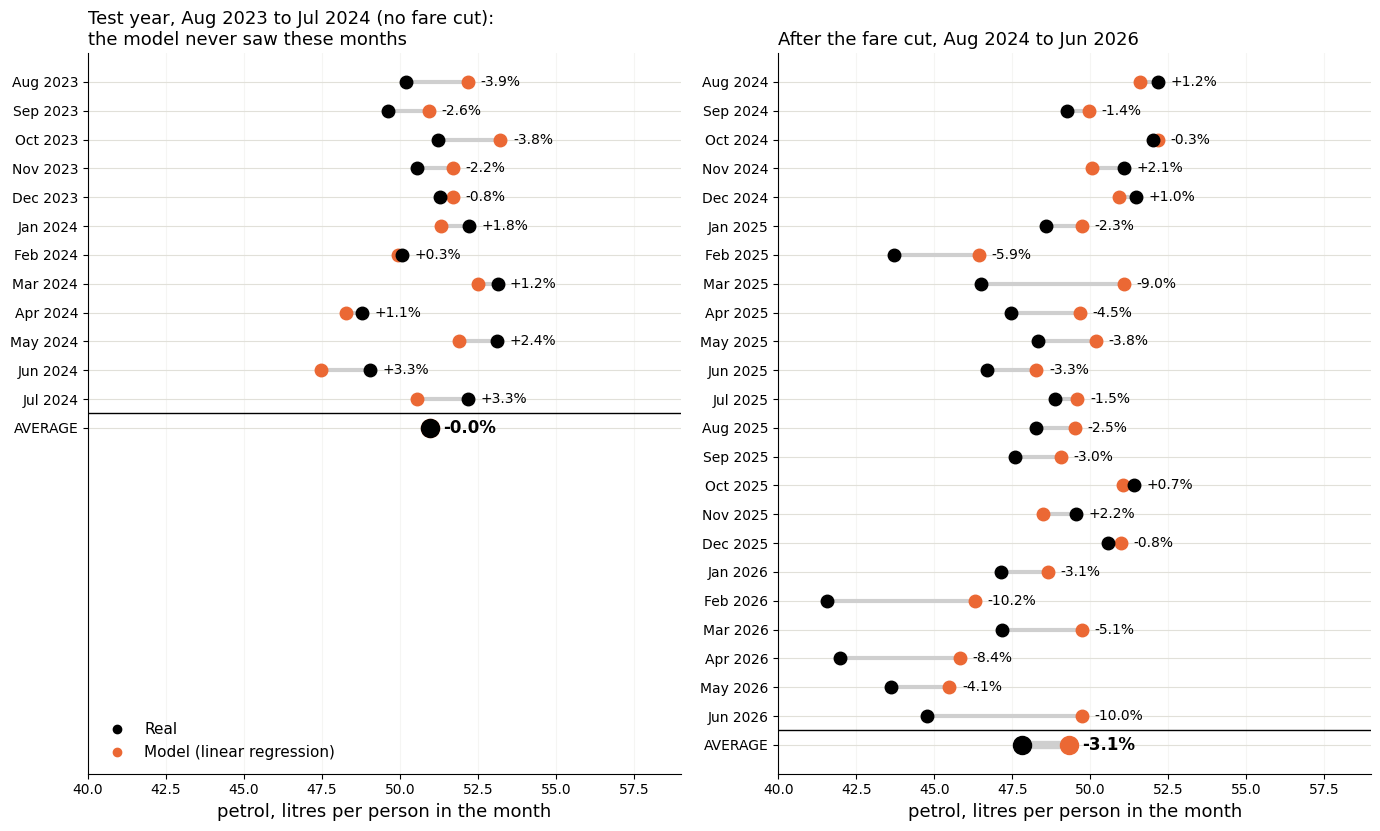

In [26]:
# Petrol month by month, best model: the real figure (black) against linear regression (orange), one row per month,
# with the average of the period at the bottom. The percentage is how far the real figure is from the model's.
petrol_df, lin = files["Petrol"]["df"], predictions[("Petrol", "Linear regression", "main")]
parts = [("Test year, Aug 2023 to Jul 2024 (no fare cut):\nthe model never saw these months", "validation"),
         ("After the fare cut, Aug 2024 to Jun 2026", "policy")]
fig, axes = plt.subplots(1, 2, figsize=(14, 8.5), sharex=True)
for ax, (title, split) in zip(axes, parts):
    rows = petrol_df.index[petrol_df["split"] == split]
    actual, model = petrol_df.loc[rows, "qld_litres_pp"], lin.reindex(rows)
    labels = [t.strftime("%b %Y") for t in rows] + ["AVERAGE"]
    ys = [24 - i for i in range(len(labels))]                       # both panels share the row spacing, top-aligned
    for y, a, m, lab in zip(ys, list(actual) + [actual.mean()], list(model) + [model.mean()], labels):
        big = lab == "AVERAGE"
        ax.plot([m, a], [y, y], color="#cfcfcf", lw=6 if big else 3)
        ax.plot(m, y, "o", color=COLOURS["Linear regression"], ms=13 if big else 9)
        ax.plot(a, y, "o", color="black", ms=13 if big else 9)
        ax.text(max(a, m) + 0.4, y, f"{a / m - 1:+.1%}", va="center", fontsize=12 if big else 10, fontweight="bold" if big else "normal")
    ax.axhline(ys[-1] + 0.5, color="black", lw=1)
    ax.set(yticks=ys, yticklabels=labels, ylim=(0, 25), xlim=(40, 59), xlabel="petrol, litres per person in the month")
    ax.set_title(title, fontsize=13, loc="left")
    ax.tick_params(labelsize=10)
    ax.grid(axis="x", alpha=0.3)
axes[0].plot([], [], "o", color="black", label="Real")
axes[0].plot([], [], "o", color=COLOURS["Linear regression"], label="Model (linear regression)")
axes[0].legend(fontsize=11, loc="lower left")
fig.tight_layout()
plt.show()

One row per month: the black dot is what really happened, the orange dot is what the best petrol model expected, and the number is
the difference. In the test year, which the model never saw, the misses run up to 4 per cent either way and average out to zero.
After the fare cut, 18 of the 23 months sit below the model and the average is 3 per cent less.

**TLDR:** the model is good to within 4 per cent for a month and within half a per cent for a year, so we claim the year, never a month.

### Fake fare-cut dates

Can three models all be wrong together? One way to find out is to lie to them: pretend the fare was cut on a date when nothing
happened, hide everything after it, and run the same steps. The gap they find then is the gap that appears by chance.

In [27]:
# A fake fare cut: tune on the year before the cut (if COVID empties it, the last usable year before that), fit on every
# usable row before the cut, predict the months after it. Cuts before COVID stop at March 2020. The real date through this
# code gives the same gaps as the main run.
COVID = pd.Timestamp("2020-03-01")


def fake_cut(name, cut, months=12):
    f = files[name]
    df, target = f["df"], f["target"]
    usable = df.index[df[target].notna() & (df["split"] != "unused")]
    before = usable[usable < cut]
    held = before[(before >= cut - pd.DateOffset(years=2)) & (before < cut - pd.DateOffset(years=1))]
    if len(held) < (150 if f["daily"] else 6):
        held = before[before < cut - pd.DateOffset(years=1)][-(365 if f["daily"] else 12):]
    end = min(cut + pd.DateOffset(months=months), COVID) if cut < COVID else cut + pd.DateOffset(months=months)
    after = usable[(usable >= cut) & (usable < end)]
    preds = {}
    for model, fit in models.items():
        tried = [(score(df.loc[held, target], fit(f, before[before < held.min()], held, "main", p))["error"], p)
                 for p in settings_to_try(model, f)]
        preds[model] = fit(f, before, after, "main", min(tried, key=lambda x: round(x[0], 6))[1])
    return df.loc[after, target], preds

In [28]:
# Fake cuts from 2016 to 2023 and the real one, twelve months after each. A few minutes, mostly NO2.
CUTS = {"Petrol": ["2017-08-01", "2018-08-01", "2019-08-01", "2022-08-01", "2023-08-01", "2024-08-01"],
        "NO2": ["2018-08-01", "2019-08-01", "2022-08-01", "2023-08-01", "2024-08-05"],
        "Cars": ["2016-08-01", "2017-08-01", "2018-08-01", "2019-08-01", "2022-08-01", "2023-08-01", "2024-08-01"]}
fake_gaps = []
for name, cuts in CUTS.items():
    for cut in map(pd.Timestamp, cuts):
        actual, preds = fake_cut(name, cut)
        fake_gaps += [{"file": name, "cut": str(cut.year), "kind": "real" if cut.year == 2024 else "fake", "model": model,
                       "gap": score(actual, pred)["gap"]} for model, pred in preds.items()]
fake_gaps = pd.DataFrame(fake_gaps)
fake_table = fake_gaps.pivot_table(index=["file", "cut", "kind"], columns="model", values="gap")[list(models)].loc[list(files)].round(1)
fake_table.columns.name = None
fake_table

Linear regression  Gradient boosting  Random forest
file   cut  kind                                                     
Petrol 2017 fake               -1.8               -0.9           -1.2
       2018 fake               -2.4               -2.8           -1.8
       2019 fake               -1.1               -0.6           -0.8
       2022 fake                1.0                0.6            0.3
       2023 fake               -0.0               -0.2           -0.4
       2024 real               -2.3               -3.1           -3.1
NO2    2018 fake                6.0               12.1           11.5
       2019 fake                2.2               -9.0           -2.2
       2022 fake               -7.3              -14.0          -10.0
       2023 fake               -6.6               -7.1           -7.4
       2024 real                2.6                5.1            7.4
Cars   2016 fake               -0.4               -0.6           -0.6
       2017 fake               -2.2               -1.4           -2.4
       2018 fake               -3.3               -1.8           -2.1
       2019 fake               -3.5               -0.5           -3.1
       2022 fake                4.6                3.9            2.7
       2023 fake                2.1                0.9            1.5
       2024 real                0.4               -0.7           -0.4

Each cell is the gap the models found in the twelve months after a cut that never happened; 2024 is the real one, and 2019 runs only
to March 2020. For NO2 and cars the real gap sits inside the range of the fake ones. For petrol the real drop is the biggest and the
2022 and 2023 fakes show nothing, but 2018 shows a drop of 2 to 3 per cent with no fare change.

**TLDR:** by chance alone the models find gaps of up to about 3 per cent for petrol, 4 for cars and 14 for NO2; only petrol's real gap stands out, and not by much.

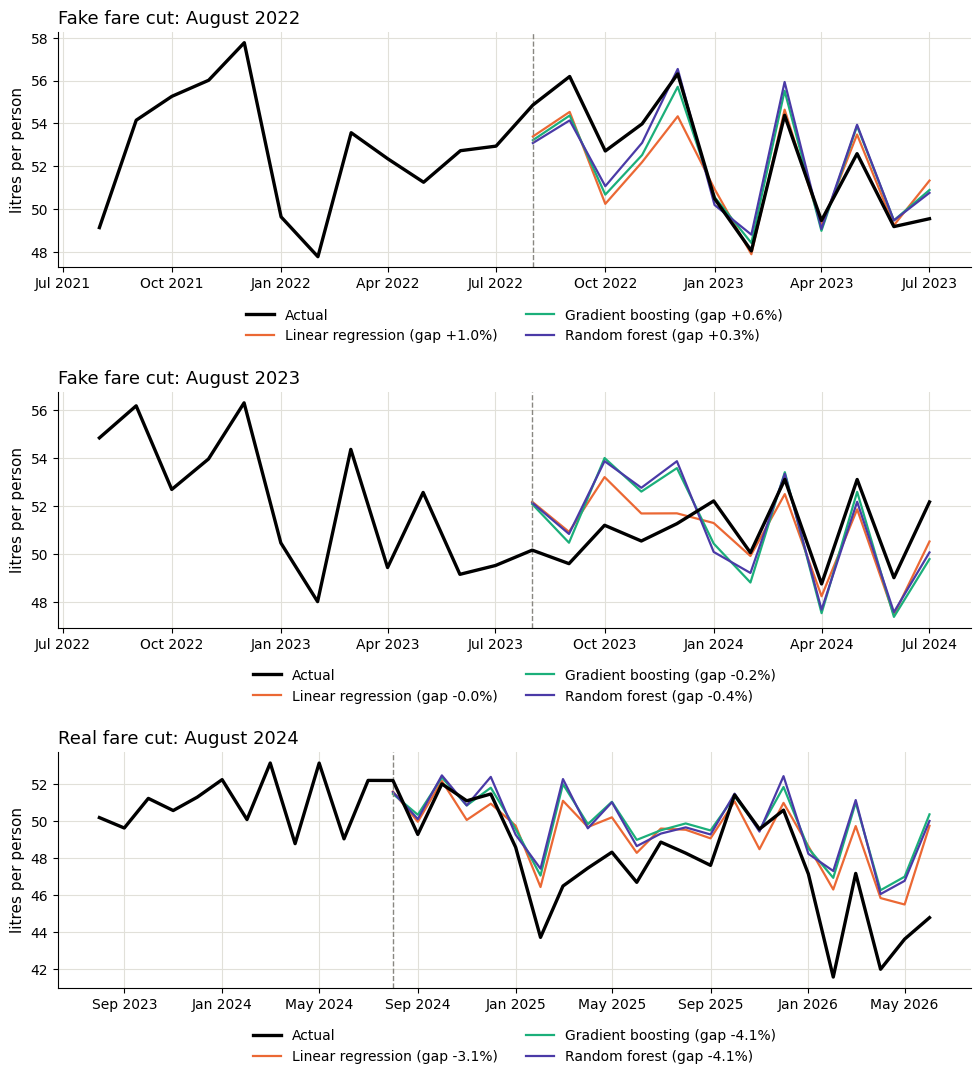

In [29]:
# Petrol after a fake fare cut in 2022 and 2023, and after the real one. The twelve months before each cut are shown for context.
import matplotlib.dates as mdates
panels = [("Fake fare cut: August 2022", "2022-08-01", 12), ("Fake fare cut: August 2023", "2023-08-01", 12),
          ("Real fare cut: August 2024", "2024-08-01", 23)]
fig, axes = plt.subplots(3, 1, figsize=(10, 11))
for ax, (title, cut, months) in zip(axes, panels):
    cut = pd.Timestamp(cut)
    actual, preds = fake_cut("Petrol", cut, months)
    ax.plot(files["Petrol"]["df"]["qld_litres_pp"][cut - pd.DateOffset(months=12):actual.index[-1]], color="black", lw=2.4, label="Actual", zorder=5)
    for model, pred in preds.items():
        ax.plot(pred, color=COLOURS[model], lw=1.6, label=f"{model} (gap {score(actual, pred)['gap']:+.1f}%)")
    ax.axvline(cut, color=GREY, ls="--", lw=1)
    ax.set_title(title, fontsize=13)
    ax.set_ylabel("litres per person", fontsize=11)
    ax.tick_params(labelsize=10)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
    ax.legend(fontsize=10, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.12))
fig.tight_layout()
plt.show()

Same models, same steps, only the date moved. After the fake cuts of 2022 and 2023 the coloured lines sit on the black one and the
gaps are within one per cent. After the real cut the black line drops below every model and stays there for two years.

**TLDR:** the models find nothing when nothing happened in 2022 and 2023, and 3 to 4 per cent less petrol after the real fare cut.

NO2 and cars: the real bars are no taller than the fake ones, so no change we can see. Petrol: the real bars are the tallest, but
2018 comes close, which is why the petrol result is "moderately sure" rather than certain.

**TLDR:** the fake dates set the bar for what counts as a change: about 3 per cent for petrol, 4 for cars and 14 for NO2.

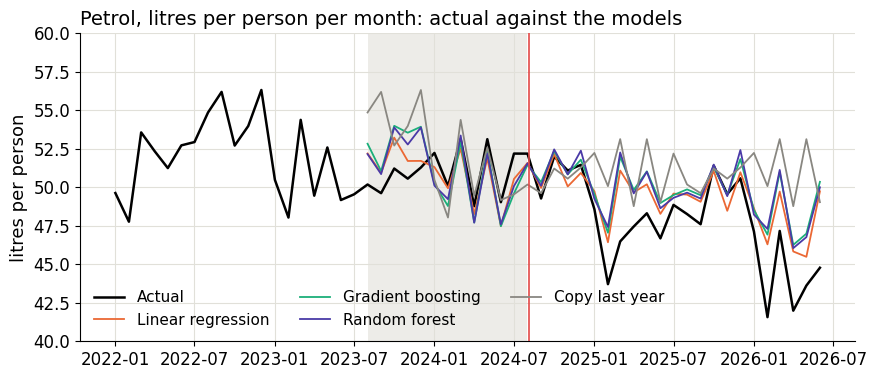

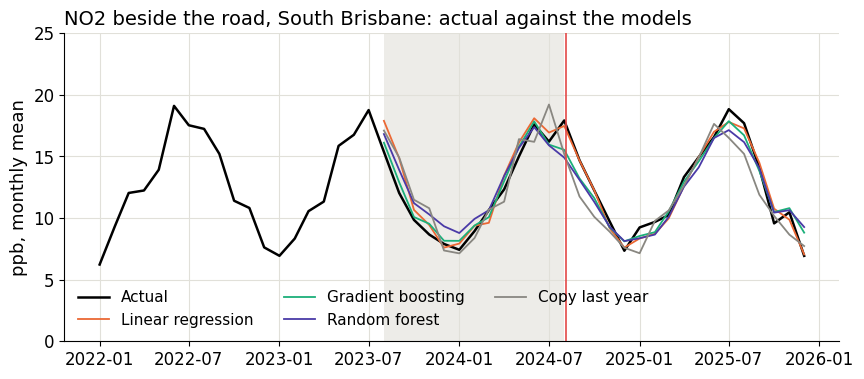

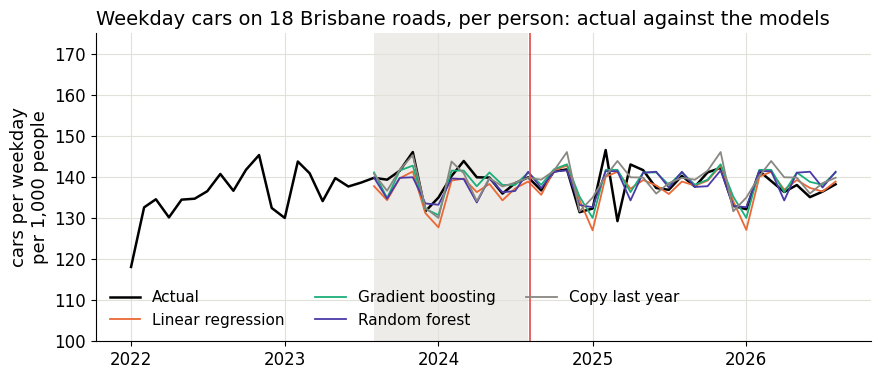

In [31]:
# Actual in black, each model in its colour, the grey copy-last-year line. The grey band is the test year.
# Daily NO2 is averaged by month so the lines can be read.
for name, f in files.items():
    monthly = (lambda s: s.resample("MS").mean()) if f["daily"] else (lambda s: s)
    actual = monthly(f["df"][f["target"]].where(f["df"]["split"] != "unused"))
    fig, ax = plt.subplots()
    ax.axvspan(pd.Timestamp("2023-08-01"), pd.Timestamp("2024-07-31"), color="#e1e0d9", alpha=0.6, lw=0)
    ax.plot(actual["2022":].index, actual["2022":], color="black", lw=1.8, label="Actual")
    for model in order:
        pred = monthly(predictions[(name, model, "main")])
        ax.plot(pred.index, pred, color=COLOURS[model], lw=1.3, label=model)
    fare_line(ax)
    ax.set_ylim(*f["ylim"])
    ax.set_ylabel(f["unit"])
    ax.set_title(f"{f['label']}: actual against the models")
    ax.legend(ncol=3, fontsize=11, loc="lower left")
    plt.show()

How to read these. The black line is what actually happened. The coloured lines are what each model expected. In the grey band,
the test year, the models had never seen the data, so that is how close they normally get. After the red line, the space between
the black line and the coloured lines is the effect of the fare. Petrol: black below the colours, less petrol than expected.
NO2: black on top of the colours, no change. Cars: black on the colours too, no change. The grey line is copy last year, the simplest model.

**TLDR:** after the red line, petrol sits below what the models expected; NO2 and cars sit right on it.

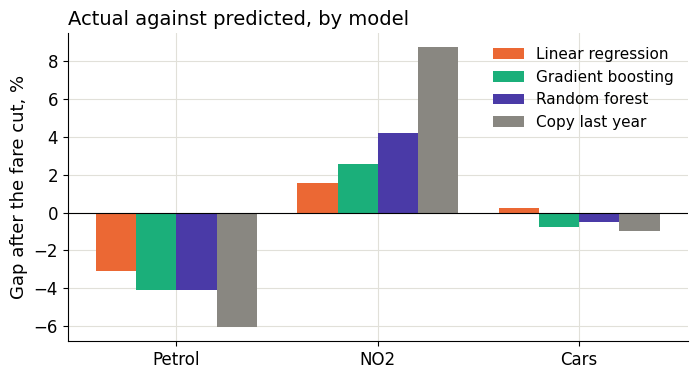

In [32]:
# All the gaps in one picture: bars above zero mean more than expected, below zero less.
main = results[results["run"] == "main"].pivot(index="file", columns="model", values="gap").loc[list(files), order]
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(files))
for i, model in enumerate(order):
    ax.bar(x + (i - 1.5) * 0.2, main[model], width=0.2, color=COLOURS[model], label=model)
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(x)
ax.set_xticklabels(list(files))
ax.set_ylabel("Gap after the fare cut, %")
ax.set_title("Actual against predicted, by model")
ax.legend(fontsize=11)
plt.show()

The same gaps as the table, drawn as bars. Below the line means less than expected, above means more. Three different models
agreeing in each group is the point: petrol down, NO2 and cars not down. The grey bar is copy last year.

**TLDR:** three models, one answer: less petrol, no cleaner air, no fewer cars.

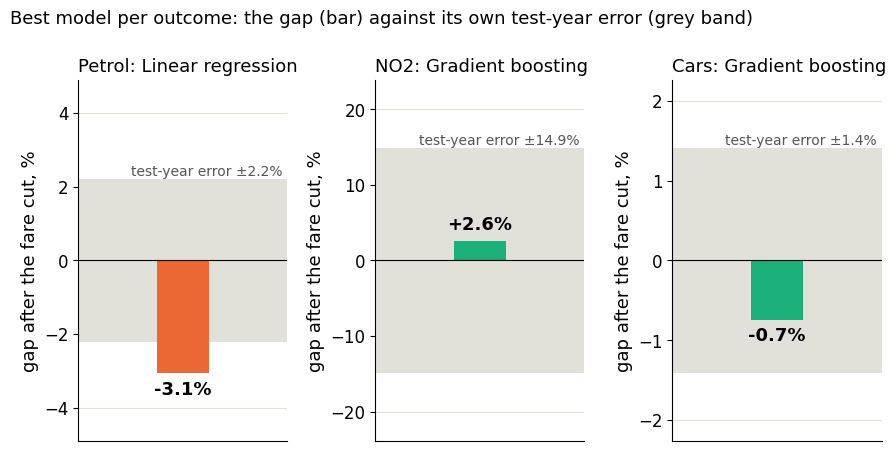

In [33]:
# The best model for each question, chosen on the test year only (lowest error), and its gap after the fare cut as one bar.
# The grey band is plus or minus that model's own test-year error: a bar that stays inside the band is no change we can see.
best = (results[(results["run"] == "main") & (results["model"] != "Copy last year")]
        .sort_values("error").groupby("file").head(1).set_index("file").loc[list(files)])
fig, axes = plt.subplots(1, 3, figsize=(9, 4.6))
for ax, (name, row) in zip(axes, best.iterrows()):
    lim = 1.6 * max(abs(row["gap"]), row["error"])
    ax.axhspan(-row["error"], row["error"], color="#e1e0d9", lw=0)
    ax.bar([0], [row["gap"]], width=0.5, color=COLOURS[row["model"]])
    ax.axhline(0, color="black", lw=0.8)
    ax.text(0, row["gap"] + (0.04 if row["gap"] >= 0 else -0.04) * lim, f"{row['gap']:+.1f}%", ha="center",
            va="bottom" if row["gap"] >= 0 else "top", fontsize=13, fontweight="bold")
    ax.text(0.95, row["error"], f"test-year error ±{row['error']:.1f}%", ha="right", va="bottom", fontsize=10, color="#555555")
    ax.set(xlim=(-1, 1), ylim=(-lim, lim), xticks=[])
    ax.set_title(f"{name}: {row['model']}", fontsize=13)
    ax.set_ylabel("gap after the fare cut, %")
fig.suptitle("Best model per outcome: the gap (bar) against its own test-year error (grey band)", fontsize=13, x=0.01, ha="left")
fig.tight_layout()
plt.show()

One bar per outcome, from the model that did best on the test year: linear regression for petrol, gradient boosting for NO2 and
cars. The grey band is how far that model normally misses. Petrol's bar reaches past its band; the NO2 and cars bars stay inside theirs.

**TLDR:** the best model says less petrol, and no change we can see in roadside air or weekday cars.

### Carbon and money

In [34]:
# Litres per person saved each month (predicted minus actual), times the population, times 2.31 kg of CO2 per litre, and times
# the pump price for dollars. Gross figures: the extra buses and trains are not taken off.
pol = petrol[petrol["split"] == "policy"]
saved, running = [], {}
for model in order:
    per_person = predictions[("Petrol", model, "main")].reindex(pol.index) - pol["qld_litres_pp"]
    litres = per_person * pol["qld_pop"]
    co2_kt = litres * 2.31 / 1e6
    dollars_m = per_person * pol["qld_avg_price_cpl"] / 100 * pol["qld_pop"] / 1e6
    running[model] = co2_kt.cumsum()
    saved.append({"Model": model, "Months": len(pol), "Petrol avoided, million litres": litres.sum() / 1e6,
                  "CO2 avoided, thousand tonnes": co2_kt.sum(), "Not spent on petrol, $ million": dollars_m.sum()})
pd.DataFrame(saved).set_index("Model").round(0).astype(int)

,Months,"Petrol avoided, million litres","CO2 avoided, thousand tonnes","Not spent on petrol, $ million"
Model,,,,
Linear regression,23,198,458,379
Gradient boosting,23,268,620,514
Random forest,23,267,617,512
Copy last year,23,405,935,781


Each row turns one model's petrol gap into litres, CO2 and dollars: litres per person saved each month, times the population,
times 2.31 kg of CO2 per litre, times the pump price. A model that found a bigger gap gives a bigger number. It is petrol only
and it does not take off the extra buses and trains, so treat it as the size of the saving, not a precise figure.

**TLDR:** roughly half a million tonnes of CO2 and about 400 million dollars of petrol not bought in 23 months, from petrol alone.

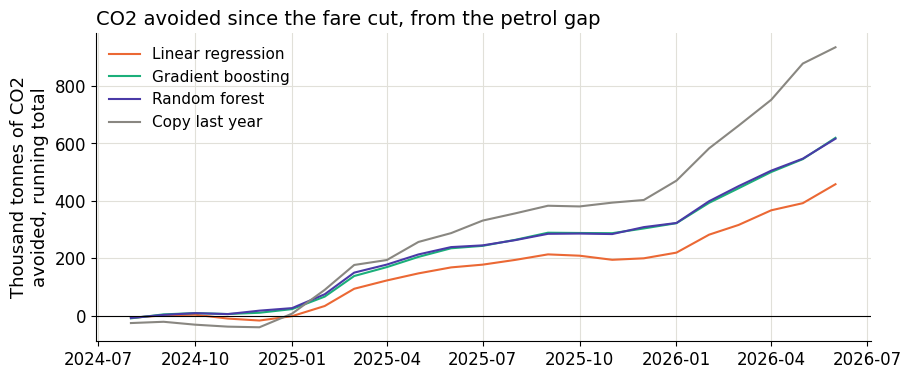

In [35]:
# These lines are running totals of (predicted minus actual), not the predictions themselves. Every month the real petrol
# figure comes in a bit below what the model expected, that difference is added to the pile, and the pile grows.
# Copy last year climbs highest because its prediction never changes: the same twelve 2023-24 numbers repeated forever.
# Petrol use falls a little every year anyway, so each month lands below the copy and the whole normal decline gets
# counted as "avoided". The real models watch NSW and Victoria, where petrol is falling for the same reasons, so their
# predictions fall too and only the part Queensland fell beyond them is counted. That is why their lines sit lower.
fig, ax = plt.subplots()
for model, r in running.items():
    ax.plot(r.index, r, color=COLOURS[model], lw=1.5, label=model)
ax.axhline(0, color="black", lw=0.8)
ax.set_ylabel("Thousand tonnes of CO2\navoided, running total")
ax.set_title("CO2 avoided since the fare cut, from the petrol gap")
ax.legend(fontsize=11)
plt.show()

Each line adds up the CO2 saved month by month since the fare cut, according to one model. Where a line ends is the total so far:
460 to 620 thousand tonnes by June 2026, roughly a year's exhaust from 100,000 to 130,000 cars, worth 380 to 510 million dollars
at the pump. The grey line is higher only because petrol use was falling anyway.

**TLDR:** the saving keeps growing month by month and had reached 460 to 620 thousand tonnes by mid 2026.

### Is it cleaner cars, or a switch to diesel?

We found less petrol but the same number of cars. Two easy explanations: the cars got cleaner (hybrids and electrics), or people
swapped petrol cars for diesel utes. Same driving, different fuel. We check both.

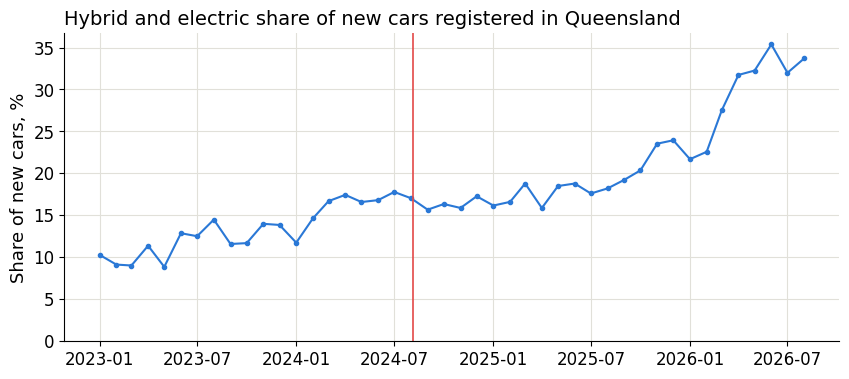

In [36]:
# New cars registered in Queensland each month by fuel type, from Transport and Main Roads (collected by Yang). September 2026 is a part month.
regs = pd.read_csv(f"{RAW}/vehicle_registrations/qld_new_registrations_monthly_by_fuel.csv", parse_dates=["month"])
regs = regs.pivot(index="month", columns="FUEL_TYPE", values="registrations").fillna(0)[:"2026-08-01"]
cleaner_share = 100 * (regs["Electric"] + regs["Petrol And Electric"] + regs["Diesel and Electric"]) / regs["All fuel types"]
fig, ax = plt.subplots()
ax.plot(cleaner_share.index, cleaner_share, color=BLUE, marker="o", ms=3)
fare_line(ax)
ax.set_ylim(0, None)
ax.set_ylabel("Share of new cars, %")
ax.set_title("Hybrid and electric share of new cars registered in Queensland")
plt.show()

Cleaner cars are arriving fast. One new car in ten was a hybrid or electric at the start of 2023; one in three by mid 2026.
But on its own that proves nothing, because NSW and Victoria are buying them too, and our petrol comparison is against those
states. The question is whether Queensland went cleaner faster than they did.

**TLDR:** Queensland is buying hybrids and electrics fast, but so is everyone else.

In [37]:
# Every registered vehicle by fuel type at 31 January, for the three states, from BITRE, Road Vehicles Australia, January 2025, table 5.
# This is the whole fleet on the road, not just new sales, so it shows how fast each state is actually going electric.
# The report is only published as a PDF, so the counts are typed in. Each list has nine numbers in the same order:
# QLD 2023, 2024, 2025, then NSW 2023, 2024, 2025, then VIC 2023, 2024, 2025. So the first number in each list is Queensland
# in January 2023: 3,008,713 petrol vehicles, 1,480,352 diesel, 72,461 hybrid, 16,715 electric, 4,598,626 in total.
# Total is bigger than the four added up because it also includes LPG and a few other fuels we do not use.
fleet = pd.DataFrame({
    "state": ["QLD"] * 3 + ["NSW"] * 3 + ["VIC"] * 3, "year": [2023, 2024, 2025] * 3,
    "petrol":   [3008713, 3039720, 3042238, 4342263, 4348041, 4310835, 3789728, 3813178, 3843145],
    "diesel":   [1480352, 1563982, 1638716, 1637342, 1709896, 1762690, 1393070, 1454324, 1516619],
    "hybrid":   [72461, 95896, 139333, 125856, 163948, 236943, 86734, 117843, 175034],
    "electric": [16715, 36280, 55661, 24789, 52505, 78317, 20125, 42859, 68370],
    "total":    [4598626, 4754324, 4892464, 6155747, 6296646, 6407874, 5387321, 5517628, 5686171]}).set_index(["state", "year"])
share = pd.DataFrame({"Hybrid or electric": 100 * (fleet["hybrid"] + fleet["electric"]) / fleet["total"],
                      "Diesel": 100 * fleet["diesel"] / fleet["total"]})
fleet_table = pd.DataFrame({f"{kind}, {year}": share.xs(year, level="year")[kind] for kind in share for year in (2023, 2025)})
for kind in share:
    fleet_table[f"{kind}, change"] = fleet_table[f"{kind}, 2025"] - fleet_table[f"{kind}, 2023"]
fleet_table = fleet_table[[c for kind in share for c in fleet_table if c.startswith(kind)]].loc[["QLD", "NSW", "VIC"]].round(1)
fleet_table.index.name = None
fleet_table      # share of all registered vehicles, per cent

,"Hybrid or electric, 2023","Hybrid or electric, 2025","Hybrid or electric, change","Diesel, 2023","Diesel, 2025","Diesel, change"
QLD,1.9,4.0,2.0,32.2,33.5,1.3
NSW,2.4,4.9,2.5,26.6,27.5,0.9
VIC,2.0,4.3,2.3,25.9,26.7,0.8


This table counts every registered vehicle in each state by what it runs on, in January 2023 and January 2025, and turns the
counts into shares. It didn't happen. Queensland's hybrid and electric share of all vehicles grew 2.0 points, against 2.5 in NSW
and 2.3 in Victoria. So cleaner cars cannot be why Queensland's petrol fell compared with those states.

**TLDR:** Queensland is going electric slower than NSW and Victoria, so electric cars do not explain the petrol drop.

Diesel is the other suspect. Queensland's diesel share grew faster than theirs (utes and large SUVs). If people swapped petrol for
diesel, petrol goes down and diesel goes up, with no change in driving. So we look at the diesel too. Not all of it: most of Queensland's
diesel goes into mines, farms and trucks, which have nothing to do with commuting. Just the diesel sold at service stations, which is
what cars, utes and vans fill up with. The petroleum statistics report that separately. Here it is, drawn the same way as chart 2.

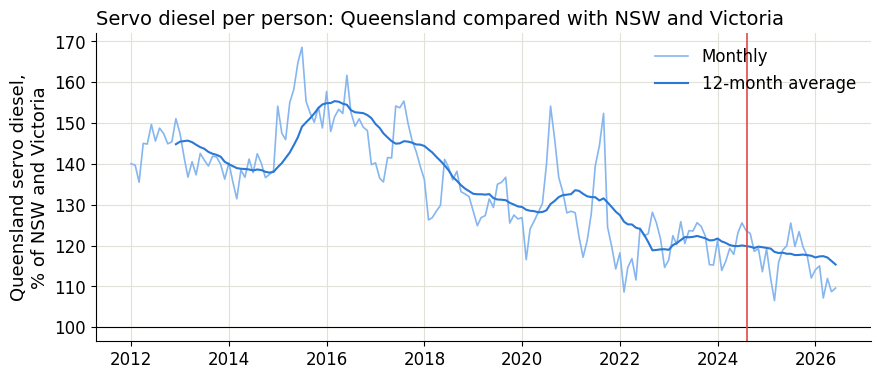

In [38]:
# Queensland's servo diesel per person as a share of NSW and Victoria's, like chart 2 for petrol.
s = (100 * petrol["qld_servo_diesel_pp"] / petrol["ctrl_servo_diesel_pp"])["2012":]
fig, ax = plt.subplots()
ax.plot(s.index, s, color="#86b6ef", lw=1.2, label="Monthly")
ax.plot(s.index, s.rolling(12).mean(), color=BLUE, label="12-month average")
ax.axhline(100, color="black", lw=0.8)
fare_line(ax)
ax.set_ylabel("Queensland servo diesel,\n% of NSW and Victoria")
ax.set_title("Servo diesel per person: Queensland compared with NSW and Victoria")
ax.legend(loc="upper right")
plt.show()

If people had swapped petrol for diesel after the fare cut, this line would have turned up at the red line. It didn't. Queensland's
servo diesel has been sliding against NSW and Victoria for a decade, and it just kept sliding.

That long slide is also why we do not forecast diesel on its own. A model trained on the years before the fare cut cannot tell the
slide apart from a fare effect, and the table below shows it: the diesel-only models are about 10 per cent off on a normal year,
far too rough to measure a 3 per cent change. Petrol and servo diesel together is the test that can be trusted.

**TLDR:** nobody swapped petrol for diesel after the fare cut; diesel kept falling as it had for years.

In [39]:
# The same three models on three versions of the fuel: petrol only, servo diesel only, and both together.
# The petroleum statistics give diesel two ways: all of it, and the part sold to retailers (servos). The second is what cars,
# utes and vans use. Mines, farms and trucking firms buy in bulk and are left out.
files["Servo diesel"] = dict(df=petrol, target="qld_servo_diesel_pp", daily=False, calendar=["month_of_year"], step=None,
                             inputs={"main": ["ctrl_servo_diesel_pp", "days_in_month"], "extra": ["ctrl_all_servo_diesel_pp", "days_in_month"]},
                             ratio={"main": "ctrl_servo_diesel_pp", "extra": "ctrl_all_servo_diesel_pp"})
files["Petrol + servo diesel"] = dict(df=petrol, target="qld_road_fuel_pp", daily=False, calendar=["month_of_year"], step=None,
                                      inputs={"main": ["ctrl_road_fuel_pp", "days_in_month"], "extra": ["ctrl_all_road_fuel_pp", "days_in_month"]},
                                      ratio={"main": "ctrl_road_fuel_pp", "extra": "ctrl_all_road_fuel_pp"})
fuel_runs = pd.concat([results[results["file"] == "Petrol"], run_file("Servo diesel"), run_file("Petrol + servo diesel")])
fuel_runs = fuel_runs[fuel_runs["run"] == "main"]
fuel_check = pd.DataFrame({f"{name}: {what}": fuel_runs[fuel_runs["file"] == name].set_index("model")[what]
                           for name in ["Petrol", "Servo diesel", "Petrol + servo diesel"] for what in ("error", "gap")}).loc[order].round(1)
fuel_check.index.name = None
fuel_check

Servo diesel: done, 93 training rows


Petrol + servo diesel: done, 93 training rows


,Petrol: error,Petrol: gap,Servo diesel: error,Servo diesel: gap,Petrol + servo diesel: error,Petrol + servo diesel: gap
Linear regression,2.2,-3.1,10.3,-10.4,1.8,-3.1
Gradient boosting,3.6,-4.1,11.1,-9.6,4.0,-4.1
Random forest,3.2,-4.1,10.7,-9.8,3.9,-4.7
Copy last year,5.0,-6.1,6.6,-2.6,5.0,-4.6


Same three models, run on three versions of the fuel. Petrol only: trustworthy, 3 to 4 per cent less than expected. Servo diesel
only: not trustworthy, the models are 10 per cent off on a normal year, so ignore that gap. Petrol and servo diesel together:
trustworthy, still 3 to 5 per cent less. If people had swapped petrol for diesel, adding the diesel back in would have cancelled
the petrol drop. It didn't. The drop is real fuel saved, not petrol moving to the diesel pump.

**TLDR:** adding diesel does not cancel the petrol drop. The fuel saving is real.

## Conclusion

Cheaper fares, cleaner air? Cheaper fares, yes. Cleaner air, no.

**What happened after the fare cut**

| | What we found | How sure |
|---|---|---|
| Public transport use | Up about 14 per cent per person, and it stayed up | Very |
| Petrol | Down 3 to 4 per cent per person compared with states that kept full fares | Fairly. The gap is a little bigger than the models' normal error |
| Cars on the road | No change. Weekday traffic on 18 main Brisbane roads, per person, is within 1 per cent of what the models expected | Very. These are the most accurate models of the lot |
| Air beside the road | No change. NO2 is where the models say it would have been anyway | Very |

If you want one number per outcome, take the model that was most accurate on the test year, the last normal year before the fare
cut, since that is the only place a model can be judged: linear regression for petrol (-3.1 per cent), gradient boosting for
NO2 (+2.6) and for cars (-0.7). The three models are close enough that this is a mild preference, not a verdict, which is why
the tables show all of them.

**The puzzle**

Less petrol, but the same number of cars. We checked the two easy explanations and neither holds up.

- Cleaner cars? No. Queensland went hybrid and electric slower than NSW and Victoria, not faster.
- A switch to diesel? No. Counting servo diesel along with petrol gives the same 3 to 5 per cent drop. Diesel fell too.

So Queenslanders really did burn less fuel: roughly 460 to 620 thousand tonnes of CO2 and 380 to 510 million dollars over 23 months,
from petrol alone. The most likely reason is driving that our counters cannot see. They count weekdays only, on inner Brisbane roads.
Weekend trips, leisure trips, shorter trips and trips in the outer suburbs would all save fuel without changing those counts, and the
modes that grew most, ferries and the Gold Coast light rail, are leisure modes. We cannot prove that with this data, so we say it as
a likely explanation, not a result.

**In one sentence**

The 50 cent fare filled the buses and trains and saved a modest amount of fuel, but it did not thin out weekday traffic and it did
not clean the air beside the road.

**Things to keep in mind**

- Fuel is counted for the whole state, but the fare matters mostly in the south east, so the real effect there is probably a bit larger.
- The air comes from one roadside sensor and the cars from 18 roads, weekdays only.
- The carbon figure does not take off the extra buses and trains, and leaves out the diesel saving.
- Brisbane Metro and the new bus network started inside the policy period.
- The fleet figures stop at January 2025, before the fastest part of the shift to hybrids.